# 🤖 Droids — balancing on a knife's edge

The robotics demo. We put Rapid Lightning where speed becomes a *capability*: the controller for an **inverted pendulum** — the textbook "don't fall over" problem, and the heart of every self-balancing robot, from a Segway to a hopping leg.

The controller is a Rapid Lightning classifier: it reads 4 sensors (cart position & velocity, pole angle & angular velocity) and decides which way to push. It compiles to a **~15 KB, zero-dependency C `.so` that decides in tens of nanoseconds** — small enough to live on a microcontroller, fast enough to run the control loop at rates a heavier model can't touch.

Two things that speed buys, and this notebook shows both:
1. **Capability** — a faster control loop rejects bigger, faster disturbances. Speed → reaction → stability margin.
2. **Practicality** — at nanoseconds per decision, the controller is *free*: it stays out of the way of the rest of the robot's compute and barely touches the battery.

*Every number below is produced by running the cell.*

In [1]:
import numpy as np, math, time
from scipy.linalg import solve_continuous_are
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
%matplotlib inline
from rapidlightning import RapidLightningClassifier
print("ready.")

ready.


## 1 · The plant — a cart-pole, and a reference controller

Standard cart-pole physics (a pole hinged on a moving cart). It's **open-loop unstable** — left alone, the pole falls. We pick a short, twitchy pole (`L=0.12`) so the dynamics are fast. As a teacher, we compute the classic **LQR** controller — optimal *if* you could run it in continuous time with full-precision force. Rapid Lightning will learn to imitate its *decisions* and then run as a tiny, fast bang-for-bang controller.

In [2]:
g, mc, mp, L = 9.8, 1.0, 0.1, 0.12   # gravity, cart mass, pole mass, pole half-length

def deriv(x, xd, th, thd, f):
    tot = mc + mp; st, ct = math.sin(th), math.cos(th)
    temp = (f + mp*L*thd*thd*st) / tot
    thacc = (g*st - ct*temp) / (L*(4.0/3.0 - mp*ct*ct/tot))
    return xd, temp - mp*L*thacc*ct/tot, thd, thacc

def rk4(s, f, dt):
    x,xd,th,thd = s
    a = deriv(x,xd,th,thd,f)
    b = deriv(x+0.5*dt*a[0], xd+0.5*dt*a[1], th+0.5*dt*a[2], thd+0.5*dt*a[3], f)
    c = deriv(x+0.5*dt*b[0], xd+0.5*dt*b[1], th+0.5*dt*b[2], thd+0.5*dt*b[3], f)
    d = deriv(x+dt*c[0], xd+dt*c[1], th+dt*c[2], thd+dt*c[3], f)
    return tuple(s[i] + dt/6*(a[i]+2*b[i]+2*c[i]+d[i]) for i in range(4))

A = np.array([[0,1,0,0],[0,0,-mp*g/mc,0],[0,0,0,1],[0,0,(mc+mp)*g/(mc*L),0]], float)
B = np.array([[0],[1.0/mc],[0],[-1.0/(mc*L)]], float)
R = np.array([[0.02]])
P = solve_continuous_are(A, B, np.diag([1.,1.,12.,1.]), R)
K = (np.linalg.inv(R) @ B.T @ P).flatten()
print("LQR gain K =", np.round(K, 2))

LQR gain K = [ -7.07 -11.16 -62.51  -9.43]


## 2 · Rapid Lightning learns to balance

We sample the state space, label each state with the LQR's decision (push left / push right), and train Rapid Lightning to imitate it. At inference we use the classifier's *probability* as a graded force (`force = Fmax·(2p − 1)`) — a confident tilt gets a hard push, near-upright gets a gentle one. Then we compile the whole controller to C.

In [3]:
rng = np.random.default_rng(0)
States = rng.uniform(low=[-1.2,-2.5,-0.35,-3.0], high=[1.2,2.5,0.35,3.0], size=(9000, 4))
labels = (States @ (-K) > 0).astype(np.int64)                 # which way LQR pushes
Xtr, Xte, ytr, yte = train_test_split(States.astype(np.float32), labels,
                                      test_size=3000, random_state=0, stratify=labels)
scaler = StandardScaler().fit(Xtr)

t0 = time.time()
clf = RapidLightningClassifier(n_members=10, generations=20, population=160, seed=1).fit(
    scaler.transform(Xtr).astype(np.float32), ytr)
imit_acc = (clf.predict(scaler.transform(Xte).astype(np.float32)) == yte).mean()
fast = clf.compile()
ns = fast.benchmark_ns()
print(f"learned the policy in {time.time()-t0:.0f}s   imitation acc={imit_acc:.3f}   {clf.n_nodes} GP nodes")
print(f"compiled controller: {fast.size_kb:.1f} KB   {ns:.1f} ns/decision   ({1e9/ns/1e6:.0f}M decisions/sec/core)")

mean = scaler.mean_.astype(np.float32); std = scaler.scale_.astype(np.float32)
def rl_force(s, Fmax=12.0):
    z = ((np.asarray(s, np.float32) - mean) / std).astype(np.float32)
    return Fmax * (2.0 * fast.predict_proba_one(z) - 1.0)   # graded force from the .so

learned the policy in 23s   imitation acc=0.988   156 GP nodes
compiled controller: 15.4 KB   19.7 ns/decision   (51M decisions/sec/core)


## 3 · Watch it balance — and watch a slow loop fail

A **continuous disturbance** beats on the pole the whole time (think vibration, wind, an uneven floor). The physics integrates finely; the **controller only updates at the control rate** (zero-order hold) — so control rate is a clean, separate dial. We run the *same* Rapid Lightning controller twice — once in a fast 200 Hz loop, once in a slow 15 Hz loop — and overlay the pole angle. Same brain, same buffeting; the only difference is how often it gets to react.

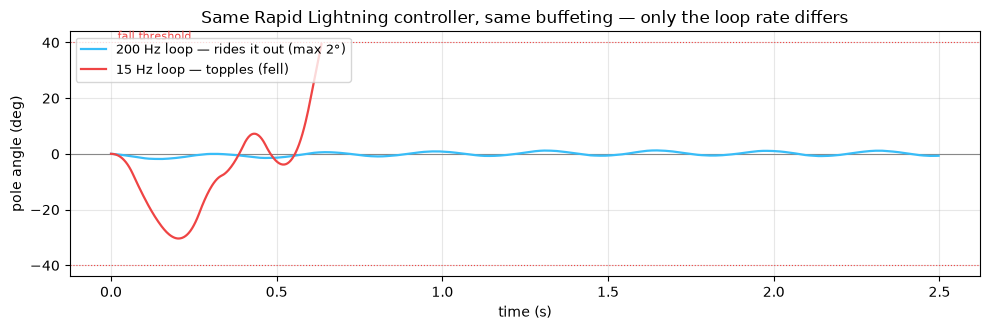

In [4]:
DISTURBANCE = 9   # buffeting amplitude (chosen so a slow loop topples and a fast one rides it out)

def simulate(control_hz, D, seed=0, T=2.5, phys_hz=6000, Fmax=14.0, fd=3.0, record=False):
    pdt = 1.0/phys_hz; spc = max(1, round(phys_hz/control_hz)); n = int(T*phys_hz)
    r = np.random.default_rng(seed)
    s = (0.0, 0.0, float(r.uniform(-0.02, 0.02)), 0.0); f = 0.0; maxang = 0.0
    ts, angs = [], []
    for i in range(n):
        if i % spc == 0: f = max(-Fmax, min(Fmax, rl_force(s, Fmax)))
        t = i*pdt
        dist = D*math.sin(2*math.pi*fd*t) + D*0.6*r.standard_normal()   # buffeting
        s = rk4(s, f + dist, pdt)
        maxang = max(maxang, abs(s[2]))
        if record and i % 15 == 0: ts.append(t); angs.append(np.degrees(s[2]))
        if abs(s[2]) > 0.7: return (False, maxang, ts, angs) if record else (False, maxang)
    return (True, maxang, ts, angs) if record else (True, maxang)

fast_ok, fast_mx, ts_f, ang_f = simulate(200, DISTURBANCE, seed=1, record=True)   # fast loop
slow_ok, slow_mx, ts_s, ang_s = simulate(15,  DISTURBANCE, seed=1, record=True)   # slow loop
plt.figure(figsize=(10, 3.4))
plt.axhline(0, color='#888', lw=.8)
plt.axhline(40, color='#ef4444', ls=':', lw=.8); plt.axhline(-40, color='#ef4444', ls=':', lw=.8)
plt.text(0.02, 41, 'fall threshold', color='#ef4444', fontsize=8)
plt.plot(ts_f, ang_f, color='#38bdf8', lw=1.6, label=f'200 Hz loop — rides it out (max {np.degrees(fast_mx):.0f}°)')
plt.plot(ts_s, ang_s, color='#ef4444', lw=1.6, label=f'15 Hz loop — topples ({"fell" if not slow_ok else "ok"})')
plt.xlabel('time (s)'); plt.ylabel('pole angle (deg)')
plt.title('Same Rapid Lightning controller, same buffeting — only the loop rate differs')
plt.legend(loc='upper left', fontsize=9); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 4 · The capability: a faster loop rides out what a slow one can't

Now the point. Same controller, same pole, same buffeting — we change **only the control rate**: how often the loop gets to react. A slow loop lags the disturbance and the tilt builds until it topples; a fast loop corrects every wobble and stays up. **That's speed becoming a capability**, not just efficiency — and Rapid Lightning's nanosecond latency is what makes the high rates affordable.

> **Why 15 Hz vs 200 Hz and not kHz?** The threshold is a property of *this* toy pole, picked so the failure is visible. Real robots run hundreds of Hz to kHz — and at those rates the budget below (§5) only tilts further toward Rapid Lightning: a heavy predictor that eats a third of a 1 kHz tick simply can't run a 10 kHz loop at all.

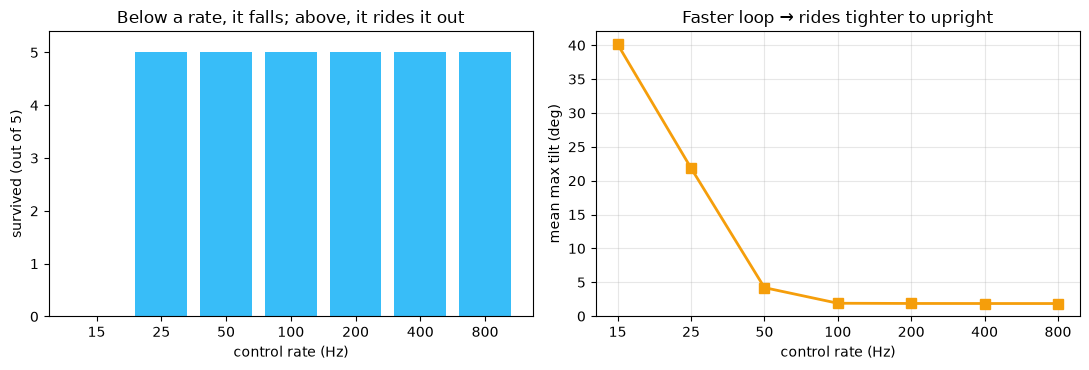

survived/5 by rate: {15: 0, 25: 5, 50: 5, 100: 5, 200: 5, 400: 5, 800: 5}


In [5]:
rates = [15, 25, 50, 100, 200, 400, 800]
survived, tilt = {}, {}
for hz in rates:
    res = [simulate(hz, DISTURBANCE, seed=k) for k in range(5)]
    survived[hz] = sum(r[0] for r in res)
    tilt[hz] = np.degrees(np.mean([r[1] for r in res]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
colors = ['#ef4444' if survived[h] < 4 else '#38bdf8' for h in rates]
ax1.bar([str(h) for h in rates], [survived[h] for h in rates], color=colors)
ax1.set_xlabel('control rate (Hz)'); ax1.set_ylabel('survived (out of 5)')
ax1.set_title('Below a rate, it falls; above, it rides it out'); ax1.set_ylim(0, 5.4)
ax2.plot([str(h) for h in rates], [tilt[h] for h in rates], 's-', color='#f59e0b', lw=2, ms=7)
ax2.set_xlabel('control rate (Hz)'); ax2.set_ylabel('mean max tilt (deg)')
ax2.set_title('Faster loop → rides tighter to upright'); ax2.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("survived/5 by rate:", {h: survived[h] for h in rates})

## 5 · Staying out of the way — the part your battery loves

The capability above assumed you *can* run the loop fast. Whether you can comes down to the controller's latency: **max control rate = 1 / latency**, and at any given rate the controller eats a slice of every tick. Here's Rapid Lightning vs. the same decision through XGBoost's Python predict.

                        RapidLightning    XGBoost (py)
latency / decision               20 ns      335,644 ns
% of a 1 kHz tick             0.0020%          33.6%
controllers / core@1kHz          50,770             3.0
max control rate              50.8 MHz         3.0 kHz
active time / decision          ~19 ns     ~335,644 ns  <- energy tracks this


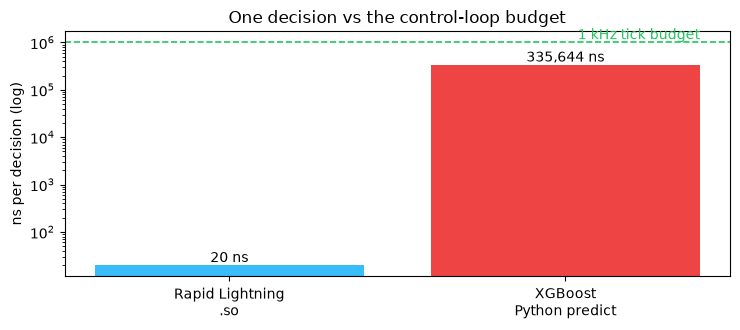

In [6]:
import xgboost as xgb
xf = xgb.XGBClassifier(n_estimators=300, max_depth=6, random_state=1, verbosity=0).fit(Xtr, ytr)
t0 = time.time()
for i in range(1500): xf.predict_proba(Xte[i:i+1])
xgb_ns = (time.time()-t0)/1500*1e9

tick = 1e6  # one 1 kHz control tick, in ns
print(f"{'':22}{'RapidLightning':>16}{'XGBoost (py)':>16}")
print(f"{'latency / decision':22}{ns:>13,.0f} ns{xgb_ns:>13,.0f} ns")
print(f"{'% of a 1 kHz tick':22}{ns/tick*100:>14.4f}%{xgb_ns/tick*100:>14.1f}%")
print(f"{'controllers / core@1kHz':22}{int(1e9/ns/1000):>16,}{1e9/xgb_ns/1000:>16.1f}")
print(f"{'max control rate':22}{1e9/ns/1e6:>12.1f} MHz{1e9/xgb_ns/1e3:>12.1f} kHz")
print(f"{'active time / decision':22}{'~'+str(int(ns))+' ns':>16}{'~'+format(int(xgb_ns),',')+' ns':>16}  <- energy tracks this")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
bars = ax.bar(['Rapid Lightning\n.so', 'XGBoost\nPython predict'], [ns, xgb_ns], color=['#38bdf8', '#ef4444'])
ax.set_yscale('log'); ax.set_ylabel('ns per decision (log)')
ax.axhline(tick, color='#22c55e', ls='--', lw=1.2); ax.text(1.4, tick, ' 1 kHz tick budget', color='#22c55e', va='bottom', ha='right')
ax.set_title('One decision vs the control-loop budget')
for b, v in zip(bars, [ns, xgb_ns]): ax.text(b.get_x()+b.get_width()/2, v, f'{v:,.0f} ns', ha='center', va='bottom')
plt.tight_layout(); plt.show()

## What you just saw

- **A 15 KB C file balanced an unstable pole** and shrugged off kicks — the whole controller is straight-line C you can read and run on a microcontroller.
- **Speed is a capability:** a faster control loop survives bigger disturbances and recovers tighter. Rapid Lightning's nanosecond latency is what makes those high rates affordable — so it buys *stability margin*, not just efficiency.
- **Speed is also "out of the way":** at a fraction of a percent of each control tick, the controller barely touches the CPU or the battery — you can run a whole robot's worth of them on one cheap chip.

Fast **and** tiny means you don't have to choose between *doing more* and *staying out of the way*. You get both.

🚀 **Next:** Spaceships — the same predictor as tiny, deterministic, auditable inference for flight & sensor hardware, where every nanosecond and every kilobyte is budgeted.